In [1]:
#0. 필요한 모듈 사용
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader  #데이터셋을 효율적으로 모델에게 공급하는 역할 - 미니배치, 랜덤하게 데이터 섞음

import matplotlib.pyplot as plt
import numpy as np

In [2]:
#1. GPU 사용환경 설정
device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [3]:
#2. 데이터 불러오기(훈련용/테스트용) -- 컴퓨터로 다운로드

# 입력이미지를 전처리 해주는 객체 생성(전처리할 것들: 텐서변환(0~255-->0~1), 크기변환, 일부 영역을 Crop, 회전, 0~1범위를 -1~1로 변환)
transform= transforms.Compose([
    transforms.ToTensor(),   #이미지를 텐서자료형으로 변환
])

# 1) 훈련용 데이터셋
train_dataset= datasets.FashionMNIST(
    root='./data',  #다운로드 된 데이터셋(이미지들)이 저장될 위치 지정
    train=True,     #훈련용으로 다운로드(6만장)
    download=True,  #만약 root에 지정한 폴더에 데이터셋이 있으면 다운로드 안함
    transform=transform  #모델의 입력 이미지 픽셀을 torch 모델의 tensor 타입으로 변환해주는 함수(객체) 지정
)

# 2) 테스트용 데이터셋
test_dataset= datasets.FashionMNIST(
    root='./data',
    train=False,     #테스트용으로 다운로드(1만장)
    download=True,
    transform=transform
)

In [4]:
#3. 데이터 확인
print(len(train_dataset))
print(len(test_dataset))

# 훈련데이터셋 중에 첫번째 이미지의 데이터 가져와보기
image, label= train_dataset[0]  #튜플(독립,종속) --> (이미지픽셀들의 3차원 텐서(1x28x28)[=Channel*Height*Width] , 라벨명(번호0~9))

print(image.shape)  # [Channel, Height, Width]
print(label)
print(train_dataset.classes)

60000
10000
torch.Size([1, 28, 28])
9
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


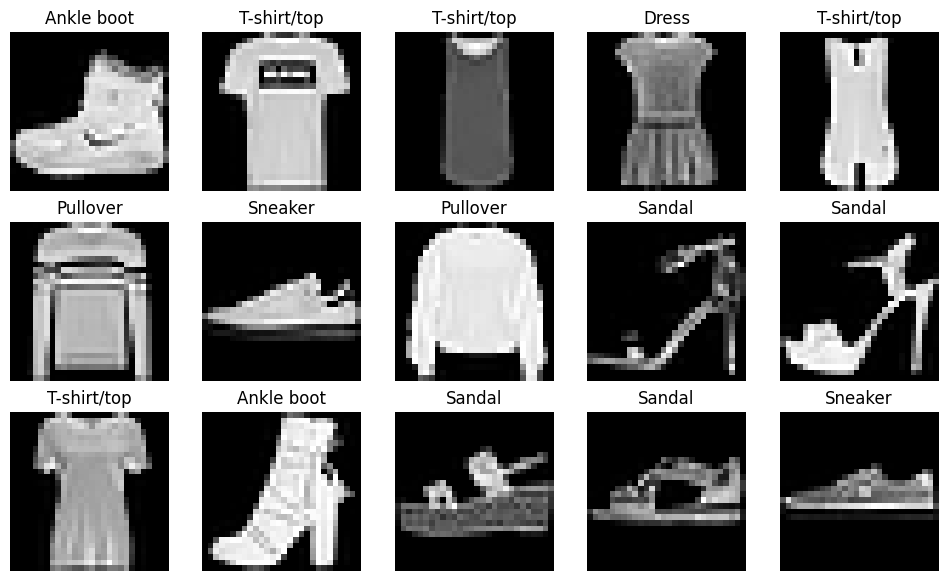

In [5]:
#4. 데이터셋 중 일부를 시각화 (이미지와, 라벨명 표시)
class_names= train_dataset.classes

# 15개 이미지 그려내기, 3행 5열로 그리기
fig, axes= plt.subplots(3, 5, figsize=(12,7))
for idx, ax in enumerate(axes.flat):
  image, label= train_dataset[idx]

  ax.imshow( image.squeeze(), cmap='gray' )  # squeeze(): 데이터의 차원 중 1인 차원을 제거. (1,28,28)-->(28,28)
  ax.set_title(class_names[label])   # 0~9 숫자로 표현되려면 --> ax.set_title(label)
  ax.axis('off')
#--------------------------------
plt.show()

In [8]:
#5. 데이터셋을 효율적으로 모델에게 학습시키기 위해 미니배치 형태로 묶고 관리해주는 DataLoader 생성

# 1) 훈련용 데이터셋 로더 생성
train_loader= DataLoader(train_dataset, batch_size=64, shuffle=True)
# 2) 테스트용 데이터셋 로더 생성
test_loader= DataLoader(test_dataset, batch_size=64, shuffle=False)  #False: 어차피 epoch를 한 번 밖에 안하니까 무의미(셔플해도 되긴한데 굳이?)

In [9]:
#6. CNN 모델 설치하기.
class FashionCNN(nn.Module):
  #초기화 메소드
  def __init__(self):
    super().__init__()

    #1) 특징 추출기(Convolution + Activation + Pooling)
    self.feature_extractor= nn.Sequential(
        #첫번째 합성곱 층 - 에지필터 사용 층
        nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),   # 28x28 --> 14x14

        #두번째 합성곱 층 -- 필터 수를 높여서 좀 더 고차원적인 특징 추출
        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),  # 14x14 --> 7x7
    )

    #2) 분류기 (Flatten + Fully Connected) -- 다중분류
    self.classifier= nn.Sequential(
        nn.Linear(64*7*7, 128),  # FC층
        nn.ReLU(),
        nn.Linear(128,10)  #출력층 -- 최종 10개의 의류를 분류
    )
  #------------- init ---------------

  # 모델에게 데이터를 주었을때 자동으로 발동하는 순전파 기능함수
  def forward(self, x):
    #1. 이미지에서 특징 추출
    x= self.feature_extractor(x)

    #2. 분류기에 넣기 위해 한줄로(1차원 텐서) 변화
    x= torch.flatten(x, start_dim=1)  #이미지 텐서값이 [배치차원,H,W] -- 0차원 제거

    #3. 최종 클래스 분류
    return self.classifier(x)

In [10]:
#7. 모델 생성 및 GPU로 이동
model= FashionCNN().to(device)
print(model)  #모델의 레이저 구조 확인

FashionCNN(
  (feature_extractor): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=3136, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [11]:
#8. 손실함수와 최적화 준비
criterion= nn.CrossEntropyLoss()
optimizer= optim.Adam(model.parameters(), lr=0.001)

In [12]:
#9. 학습
epochs= 5

for epoch in range(epochs):
  # 학습모드 켜기
  model.train()

  #배치당 손실값을 누적하여 가지고 있을 변수
  batch_total_loss=0

  #배치 단위로 학습함.
  for images, labels in train_loader:
    #CPU에 있던 데이터 묶음(배치)을 GPU 메모리로 전송
    images= images.to(device)
    labels= labels.to(device)

    #이전 배치에서 계산되어 남아있던 기울기를 초기화
    optimizer.zero_grad()

    #(순방향)
    outputs= model(images)  #독립변수에 해당하는 이미지 텐서데이터를 모델에게 주고 분류 요청

    #(손실계산)
    loss= criterion(outputs, labels)

    #(역전파 -- 새로운 기울기 계산)
    loss.backward()

    #(가중치 갱신)
    optimizer.step()

    # 이번 batch의 손실값을 누적
    batch_total_loss += loss.item()
    print(batch_total_loss)
  #----------- batch 이미지들 학습 완료 --------------

  # 1 epoch당 얼마나 손실이 발생했는지 평균..
  epoch_loss= batch_total_loss / len(train_loader)
  print(f"{epoch + 1}에포크 손실: {epoch_loss}")

1에포크 손실: 0.4535223545232561
2에포크 손실: 0.294227885308741
3에포크 손실: 0.24985729059430836
4에포크 손실: 0.22094161959408698
5에포크 손실: 0.198073355711377


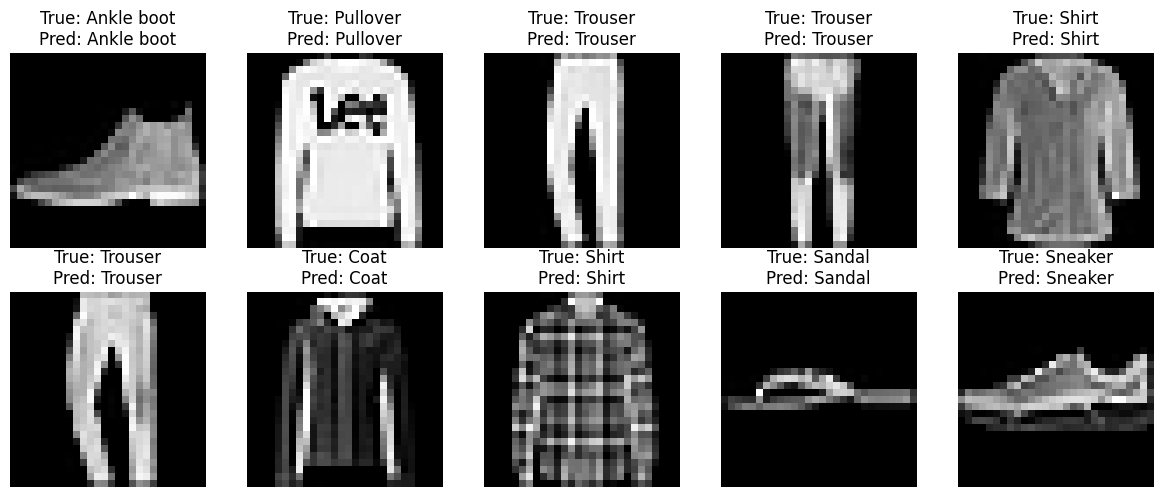

In [17]:
#10. 테스트 데이터셋 만장 중 10장만 분류 요청 시각화

# test_loader (배치단위로) 데이터를 주는 녀석에게 1배치(이미지들 64개) 주세요!!
# iter 반복자를 이용하여 1묶음만 추출
images, labels= next(iter(test_loader))

# GPU로 이동
images= images.to(device)

# 모델에게 64장의 한묶음 이미지들에 대한 분류 요청
outputs= model(images)
# output은 분류결과값을 [각 클래스별 확률값으로 줌.]
# 가장 높은 분류 확률값을 가진 인덱스 번호 추출[0~9]
_, predictions= torch.max(outputs, 1)  #각 행에서 최대값 추출 ( _ (prob), predictions->확률값, 인덱스번호)튜플을 언패킹

# 시각화를 하여 64장 중 10장의 이미지를 2행5열로 화면에 표시하기 (정답값, 예측값도 표시)
# 시각화 도구인 matplot은 CPU의 데이터만 사용가능
# GPU 데이터를 CPU로 이동
images= images.cpu()

fig, axes = plt.subplots(2, 5, figsize=(12,5))

for idx, ax in enumerate(axes.flat):
  ax.imshow(images[idx].squeeze(), cmap='gray')

  # 실제값(정답값) 0~9 --> 각 클래스명으로..
  actual= class_names[labels[idx]]

  #모델의 예측값 predictions 도 클래스명으로
  pred=class_names[predictions[idx].cpu()]

  #각 서브플롯(이미지그려진 영역)의 제목에 실제값, 예측값 표시
  ax.set_title(f"True: {actual}\nPred: {pred}")
  ax.axis('off')
#-----------반복종료

plt.tight_layout()  #제목이 겹치지 않도록...
plt.show()

In [ ]:
# 수행과제
# 파이토치 책 Part3. chapter01 MNIST 분류

# 대표적인 CNN모델들 살펴보기 위해. 딥러닝 텐서플로 교과서 책 6.1장 읽어보기